In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("customer_churn_preprocessed.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (7043, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


In [3]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nChurn Distribution:")
print(y.value_counts())

Features Shape: (7043, 30)
Target Shape: (7043,)

Churn Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (5634, 30)
Testing Features: (1409, 30)
Training Target: (5634,)
Testing Target: (1409,)


In [5]:
log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train, y_train)

log_predictions = log_model.predict(X_test)
log_probabilities = log_model.predict_proba(X_test)[:, 1]

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [6]:
dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)
dt_probabilities = dt_model.predict_proba(X_test)[:, 1]

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [7]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [8]:
models = {
    "Logistic Regression": (log_predictions, log_probabilities),
    "Decision Tree": (dt_predictions, dt_probabilities),
    "Random Forest": (rf_predictions, rf_probabilities)
}

results = []

for model_name, (predictions, probabilities) in models.items():

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)
    roc_auc = roc_auc_score(y_test, probabilities)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8041,0.6541,0.5561,0.6012,0.8428
1,Decision Tree,0.7942,0.6312,0.5401,0.5821,0.8267
2,Random Forest,0.8062,0.6700,0.5321,0.5931,0.8435


In [9]:
for model_name, (predictions, probabilities) in models.items():

    print("\n", "=" * 50)
    print(model_name)
    print("=" * 50)

    print(classification_report(
        y_test,
        predictions,
        target_names=["No Churn", "Churn"],
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.65      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.74      1409
weighted avg       0.80      0.80      0.80      1409


Decision Tree
              precision    recall  f1-score   support

    No Churn       0.84      0.89      0.86      1035
       Churn       0.63      0.54      0.58       374

    accuracy                           0.79      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.79      0.79      1409


Random Forest
              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      1035
       Churn       0.67      0.53      0.59       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.73      1409
weighted avg       0.80

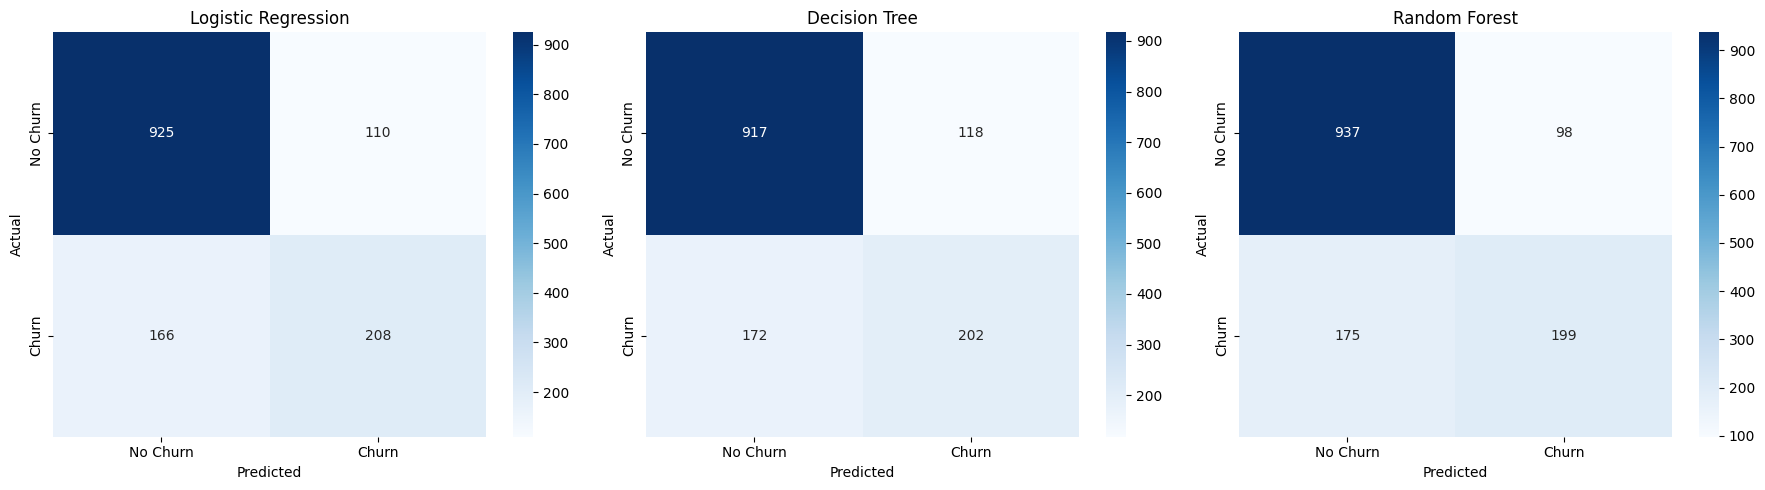

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, (predictions, probabilities)) in zip(
    axes, models.items()
):

    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

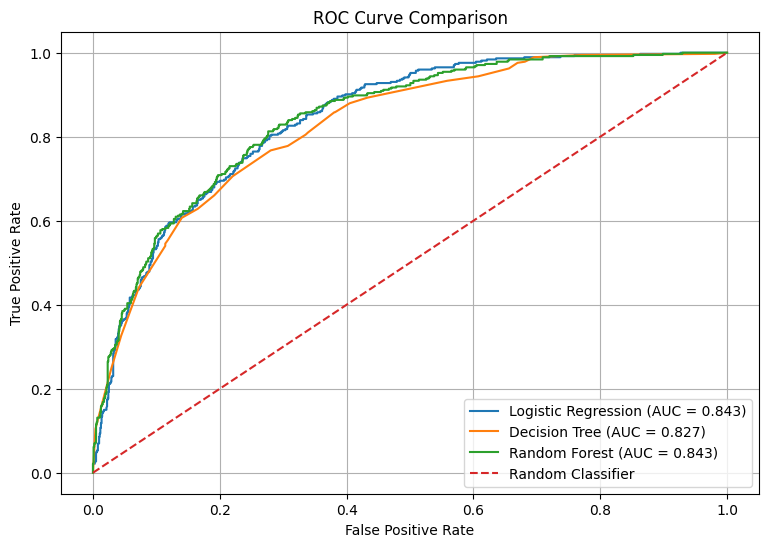

In [11]:
plt.figure(figsize=(9, 6))

for model_name, (predictions, probabilities) in models.items():

    fpr, tpr, thresholds = roc_curve(y_test, probabilities)

    auc_value = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_value:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.grid()
plt.show()

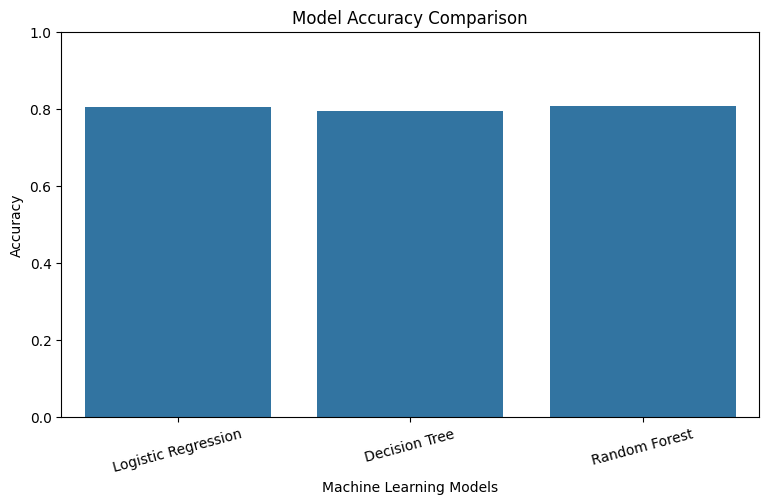

In [12]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1)

plt.xticks(rotation=15)
plt.show()

In [13]:
results_df.to_csv("customer_churn_model_comparison.csv", index=False)

print("Model comparison results saved successfully!")

Model comparison results saved successfully!


In [14]:
import joblib

joblib.dump(log_model, "logistic_regression_model.pkl")
joblib.dump(dt_model, "decision_tree_model.pkl")
joblib.dump(rf_model, "random_forest_model.pkl")

print("All three trained models saved successfully!")

All three trained models saved successfully!


In [15]:
print("CUSTOMER CHURN PREDICTION - DAY 3")
print("----------------------------------")

print("Dataset Records:", len(df))
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nModels Trained:")
print("1. Logistic Regression")
print("2. Decision Tree")
print("3. Random Forest")

print("\nModel Evaluation Completed!")
print("Comparison results and trained models saved.")

CUSTOMER CHURN PREDICTION - DAY 3
----------------------------------
Dataset Records: 7043
Training Records: 5634
Testing Records: 1409

Models Trained:
1. Logistic Regression
2. Decision Tree
3. Random Forest

Model Evaluation Completed!
Comparison results and trained models saved.
